# Task 27: Handling Class Imbalance

Compare a logistic regression baseline with a model that uses `class_weight="balanced"` to account for a minority churn class. We will inspect the original target distribution and compare precision, recall, and F1 on the same held-out test data. Accuracy is included for context, but can hide poor minority-class performance.

The bundled `customer_churn.csv` is synthetic and contains no real customer data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

ModuleNotFoundError: No module named 'pandas'

## 1. Load the data and inspect the original class distribution

The imbalance ratio is the number of majority-class records divided by the number of minority-class records.

,Customer status,Count,Percentage
0,Stayed (0),1541,77.05
1,Churned (1),459,22.95


Majority-to-minority imbalance ratio: 3.36:1


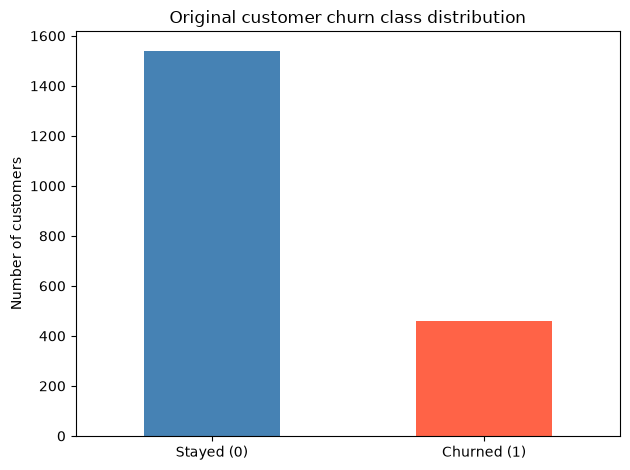

In [ ]:
df = pd.read_csv("customer_churn.csv")
target = "Churn"

if target not in df.columns:
    raise ValueError(f"Expected target column {target!r} in the dataset.")
if df[target].isna().any() or not set(df[target].unique()).issubset({0, 1}):
    raise ValueError("Churn must contain only non-null binary values 0 and 1.")

class_counts = df[target].value_counts().sort_index()
class_percentages = df[target].value_counts(normalize=True).sort_index() * 100
majority_count = int(class_counts.max())
minority_count = int(class_counts.min())

distribution = pd.DataFrame({
    "Customer status": ["Stayed (0)", "Churned (1)"],
    "Count": [int(class_counts.get(0, 0)), int(class_counts.get(1, 0))],
    "Percentage": [class_percentages.get(0, 0.0), class_percentages.get(1, 0.0)],
})
display(distribution.round({"Percentage": 2}))
print(f"Majority-to-minority imbalance ratio: {majority_count / minority_count:.2f}:1")

ax = distribution.plot.bar(x="Customer status", y="Count", legend=False, color=["steelblue", "tomato"])
ax.set_title("Original customer churn class distribution")
ax.set_ylabel("Number of customers")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Split the data and define leakage-safe preprocessing

A stratified split preserves the target proportions in train and test. The preprocessing transformer is part of each model pipeline, so scaling and category levels are learned from training data only. The test set is held out for evaluation.

In [ ]:
X = df.drop(columns=target)
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Training rows: 1,500; test rows: 500
Numeric features: ['TenureMonths', 'MonthlyCharges', 'SupportCalls']
Categorical features: ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling']


## 3. Fit baseline and class-weighted models

The treatment changes only the class weights. Both models receive the same training rows, preprocessing, solver settings, and random seed.

In [ ]:
models = {
    "Baseline": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Class-weighted": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
    ),
}

predictions = {}
results = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred
    results[name] = {
        "Precision (churn)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (churn)": recall_score(y_test, y_pred, zero_division=0),
        "F1 (churn)": f1_score(y_test, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_pred),
    }

for name, y_pred in predictions.items():
    print(f"\n{name} classification report")
    print(classification_report(
        y_test, y_pred, labels=[0, 1], target_names=["Stayed", "Churned"], zero_division=0
    ))


Baseline classification report
              precision    recall  f1-score   support

      Stayed       0.80      0.92      0.86       385
     Churned       0.45      0.22      0.29       115

    accuracy                           0.76       500
   macro avg       0.63      0.57      0.57       500
weighted avg       0.72      0.76      0.73       500


Class-weighted classification report
              precision    recall  f1-score   support

      Stayed       0.87      0.61      0.72       385
     Churned       0.35      0.70      0.47       115

    accuracy                           0.63       500
   macro avg       0.61      0.66      0.59       500
weighted avg       0.75      0.63      0.66       500



## 4. Compare held-out performance

Precision, recall, and F1 below refer to the positive (churned) class. The confusion matrices show counts of correct and incorrect predictions for each class.

,Precision (churn),Recall (churn),F1 (churn),Accuracy
Baseline,0.455,0.217,0.294,0.76
Class-weighted,0.349,0.704,0.467,0.63


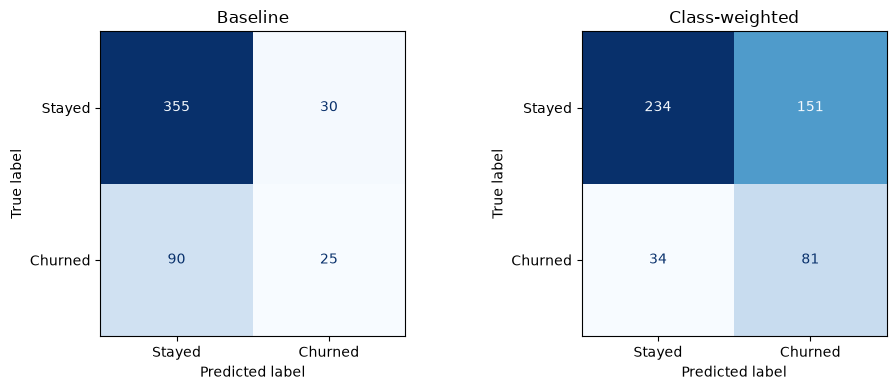

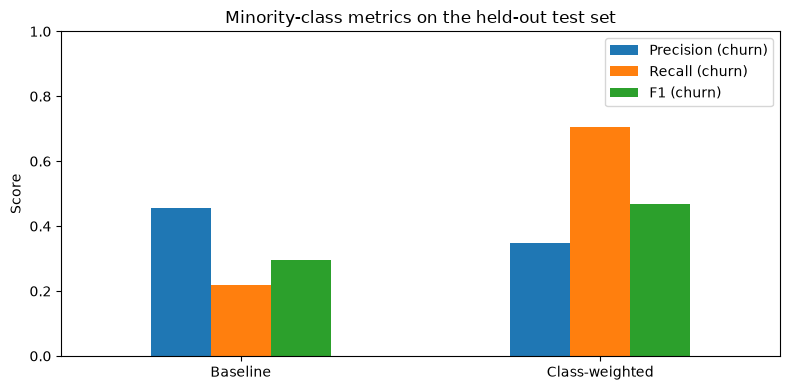

In [ ]:
comparison = pd.DataFrame.from_dict(results, orient="index")
display(comparison.round(3))

fig, axes = plt.subplots(1, len(predictions), figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["Stayed", "Churned"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

comparison[["Precision (churn)", "Recall (churn)", "F1 (churn)"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 4), rot=0
)
plt.title("Minority-class metrics on the held-out test set")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## 5. Conclusion

Compare minority-class F1, precision, and recall alongside accuracy. Balanced class weights can improve minority recall, but may trade off precision or overall accuracy. The most suitable model depends on the costs of missed churners versus unnecessary retention outreach; use the measured test-set results above rather than assuming either model is universally better.

In [ ]:
baseline = comparison.loc["Baseline"]
balanced = comparison.loc["Class-weighted"]
print("Change after applying balanced class weights (class-weighted minus baseline):")
for metric in ["Precision (churn)", "Recall (churn)", "F1 (churn)", "Accuracy"]:
    change = balanced[metric] - baseline[metric]
    print(f"{metric}: {change:+.3f}")

if balanced["F1 (churn)"] > baseline["F1 (churn)"]:
    print("\nConclusion: Balanced class weights improved held-out churn F1. Check the precision/recall trade-off and business costs before choosing it.")
else:
    print("\nConclusion: Balanced class weights did not improve held-out churn F1 in this run. Check the precision/recall trade-off and business costs before choosing a model.")

Change after applying balanced class weights (class-weighted minus baseline):
Precision (churn): -0.105
Recall (churn): +0.487
F1 (churn): +0.173
Accuracy: -0.130

Conclusion: Balanced class weights improved held-out churn F1. Check the precision/recall trade-off and business costs before choosing it.
